In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dataset = pd.read_csv("/content/drive/MyDrive/titanic.csv")
dataset.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
dataset.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [9]:
print('Median of Age column : %.2f' % (dataset['Age'].median(skipna=True)))

print('Percent of missing records in the Cabin column : %.2f'
      % ((dataset['Cabin'].isnull().sum() / dataset.shape[0]) * 100))

print('Most common boarding port of embarkation: %s'
      % dataset['Embarked'].value_counts().idxmax())


Median of Age column : 28.00
Percent of missing records in the Cabin column : 77.10
Most common boarding port of embarkation: S


In [15]:
# Fill missing values
dataset["Age"] = dataset["Age"].fillna(dataset["Age"].median(skipna=True))

dataset["Embarked"] = dataset["Embarked"].fillna(
    dataset["Embarked"].value_counts().idxmax()
)

# Drop Cabin safely
dataset.drop("Cabin", axis=1, inplace=True, errors="ignore")

# Check missing values
dataset.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [19]:
dataset.drop('PassengerId', axis=1, inplace=True, errors='ignore')
dataset.drop('Name', axis=1, inplace=True, errors='ignore')
dataset.drop('Ticket', axis=1, inplace=True, errors='ignore')

dataset.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [23]:
dataset['TravelAlone'] = np.where(
    (dataset["SibSp"] + dataset["Parch"]) > 0, 0, 1
)

dataset.drop('Parch', axis=1, inplace=True, errors='ignore')
dataset.drop('SibSp', axis=1, inplace=True, errors='ignore')

dataset.head()

,Survived,Pclass,Sex,Age,Fare,Embarked,TravelAlone
0,0,3,male,22.0,7.2500,S,0
1,1,1,female,38.0,71.2833,C,0
2,1,3,female,26.0,7.9250,S,1
3,1,1,female,35.0,53.1000,S,0
4,0,3,male,35.0,8.0500,S,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Survived     891 non-null    int64  
 1   Pclass       891 non-null    int64  
 2   Sex          891 non-null    int64  
 3   Age          891 non-null    float64
 4   Fare         891 non-null    float64
 5   Embarked     891 non-null    int64  
 6   TravelAlone  891 non-null    int64  
dtypes: float64(2), int64(5)
memory usage: 48.9 KB
Features (X):
   Pclass  Sex   Age     Fare  Embarked  TravelAlone
0       3    1  22.0   7.2500         2            0
1       1    0  38.0  71.2833         0            0
2       3    0  26.0   7.9250         2            1
3       1    0  35.0  53.1000         2            0
4       3    1  35.0   8.0500         2            1
Target (y):
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64
     Actual value  Predicted value
495             0       

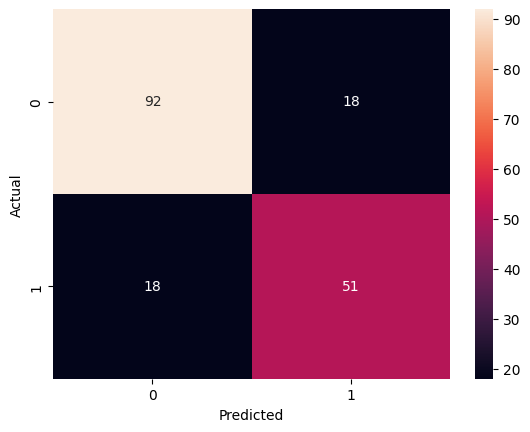

In [25]:
dataset.shape

dataset.info()

dataset.describe()

from sklearn import preprocessing
label_encoder = preprocessing.LabelEncoder()

dataset['Sex'] = label_encoder.fit_transform(dataset['Sex'])
dataset['Embarked'] = label_encoder.fit_transform(dataset['Embarked'])

X = dataset.drop('Survived', axis=1)
y = dataset['Survived']

print('Features (X):')
print(X.head())

print('Target (y):')
print(y.head())

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)

y_pred = lr_model.predict(X_test)

diff = pd.DataFrame({'Actual value': y_test, 'Predicted value': y_pred})
print(diff.head())


from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))


sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()